# ДЗ 2. Прогноз продаж

Возьмём продажи товара 20725 из ДЗ 1. Оставим полные периоды и проверим даты и частоту.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.ensemble import GradientBoostingRegressor
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing

folder = Path.cwd()
if (folder / "2").is_dir():
    folder /= "2"
data_dir = folder.parent / "1" / "results"

# Файл, частота, горизонты, число тестовых дат
settings = {
    "День": ("daily", "D", (1, 7, 31, 61), 90),
    "Неделя": ("weekly", "W-SUN", (1, 4, 8), 13),
    "Месяц": ("monthly", "MS", (1, 2), 4),
}


def load_sales(file, freq):
    frame = pd.read_csv(data_dir / f"{file}.csv", index_col="date", parse_dates=["date"])
    sales = frame.loc[frame["complete"], "units"]
    expected_dates = pd.date_range(sales.index[0], periods=len(sales), freq=freq)
    assert sales.index.equals(expected_dates)
    assert np.isfinite(sales).all() and sales.ge(0).all()
    return sales.asfreq(freq)


series = {name: load_sales(file, freq) for name, (file, freq, _, _) in settings.items()}
pd.DataFrame(
    [
        {
            "Частота": name,
            "Всего точек": len(sales),
            "Тест с": sales.index[-settings[name][3]],
            "Тест по": sales.index[-1],
        }
        for name, sales in series.items()
    ]
).set_index("Частота")

,Всего точек,Тест с,Тест по
Частота,,,
День,373,2011-09-10,2011-12-08
Неделя,52,2011-09-11,2011-12-04
Месяц,12,2011-08-01,2011-11-01


## Модели

Сравним наивный прогноз, экспоненциальное сглаживание (ETS), авторегрессию (AR) и градиентный бустинг. В наивном прогнозе повторим последнюю неделю для дней и последнее значение для недель и месяцев. Для дневного ETS добавим сезонность с периодом 7.

Для бустинга возьмём лаги, среднее по последним 7 дням или 4 неделям и день недели для дневного ряда. Будем предсказывать по одному шагу и добавлять прогноз в историю для следующего шага.

In [2]:
def naive(train, steps, period):
    return np.resize(train.to_numpy()[-period:], steps)


def ets(train, steps, period):
    values = train.to_numpy()
    if period == 1:
        model = SimpleExpSmoothing(values, initialization_method="estimated")
    else:
        model = ExponentialSmoothing(values, seasonal="add", seasonal_periods=period)
    return model.fit().forecast(steps)


def autoregression(train, steps, lags):
    values = train.to_numpy()
    return AutoReg(values, lags=list(lags)).fit().predict(start=len(values), end=len(values) + steps - 1)


def boost_features(windows, dates, lags, daily):
    features = windows[:, -np.array(lags)]
    if max(lags) > 1:
        features = np.column_stack([features, windows.mean(axis=1)])
    if daily:
        features = np.column_stack([features, dates.day_of_week])
    return features


def boosting(train, dates, lags, daily):
    window = max(lags)
    values = train.to_numpy()
    windows = sliding_window_view(values, window)
    x_train = boost_features(windows[:-1], train.index[window:], lags, daily)
    model = GradientBoostingRegressor(n_estimators=60, max_depth=2, min_samples_leaf=2, random_state=0)
    model.fit(x_train, values[window:])

    history = values.tolist()
    for i in range(len(dates)):
        recent = np.array([history[-window:]])
        features = boost_features(recent, dates[i : i + 1], lags, daily)
        history.append(max(0.0, model.predict(features)[0]))
    return history[len(values) :]


def predict(train, dates, freq):
    steps = len(dates)
    daily = freq == "D"
    period = 7 if daily else 1
    ar_lags = (1, 7) if daily else (1,)
    boost_lags = {"D": (1, 7), "W-SUN": (1, 2, 4), "MS": (1,)}[freq]
    return {
        "Naive": naive(train, steps, period),
        "ETS": ets(train, steps, period),
        "AR": autoregression(train, steps, ar_lags),
        "Boosting": boosting(train, dates, boost_lags, daily),
    }

## Проверка на тесте

Оставим в конце 90 дней, 13 недель и 4 месяца. Для каждой тестовой даты отсчитаем $h$ шагов назад и обучим модели на истории до этой границы включительно. Сравним с фактом прогноз ровно на $h$-м шаге. Так даты оценки совпадут для всех горизонтов, а окно обучения будет расширяться по мере поступления факта.

In [3]:
def backtest(sales, freq, horizons, test_size):
    first_test = len(sales) - test_size
    first_split = first_test - max(horizons) + 1
    assert first_split > 0 and test_size > 0

    rows = []
    for split in range(first_split, len(sales)):
        steps = [h for h in horizons if first_test <= split + h - 1 < len(sales)]
        if not steps:
            continue
        train = sales.iloc[:split]
        dates = sales.index[split : split + max(steps)]
        for model, forecast in predict(train, dates, freq).items():
            for h in steps:
                rows.append(
                    {
                        "model": model,
                        "horizon": h,
                        "train_end": train.index[-1],
                        "date": dates[h - 1],
                        "actual": sales.iloc[split + h - 1],
                        "prediction": max(0.0, forecast[h - 1]),
                    }
                )

    return pd.DataFrame(rows)


predictions = pd.concat(
    [
        backtest(series[name], freq, horizons, test_size).assign(frequency=name)
        for name, (_, freq, horizons, test_size) in settings.items()
    ],
    ignore_index=True,
)
predictions = predictions[["frequency", "horizon", "model", "train_end", "date", "actual", "prediction"]]
predictions.head()

,frequency,horizon,model,train_end,date,actual,prediction
0,День,61,Naive,2011-07-11,2011-09-10,0.0,0.000000
1,День,61,ETS,2011-07-11,2011-09-10,0.0,7.630686
2,День,61,AR,2011-07-11,2011-09-10,0.0,48.048115
3,День,61,Boosting,2011-07-11,2011-09-10,0.0,13.411268
4,День,61,Naive,2011-07-12,2011-09-11,22.0,12.000000


## Метрики

Посчитаем MAE в штуках и RMSE, чтобы сильнее учитывать большие промахи. Модели сравним по WAPE: поделим сумму абсолютных ошибок на сумму продаж. Отдельные нулевые дни при этом не мешают расчёту.

In [4]:
def score(predictions):
    rows = []
    for (frequency, horizon, model), group in predictions.groupby(["frequency", "horizon", "model"], sort=False):
        errors = group["actual"] - group["prediction"]
        volume = group["actual"].sum()
        rows.append(
            {
                "frequency": frequency,
                "horizon": horizon,
                "model": model,
                "n": len(group),
                "MAE": errors.abs().mean(),
                "RMSE": np.sqrt(errors.pow(2).mean()),
                "WAPE, %": 100 * errors.abs().sum() / volume,
            }
        )
    return pd.DataFrame(rows).sort_values(["frequency", "horizon", "WAPE, %"])


metrics = score(predictions)
winners = metrics.loc[metrics.groupby(["frequency", "horizon"])["WAPE, %"].idxmin()]

results = folder / "results"
results.mkdir(exist_ok=True)
predictions.to_csv(results / "predictions.csv", index=False)
metrics.to_csv(results / "metrics.csv", index=False)

display(metrics.set_index(["frequency", "horizon", "model"]).round(2))

n     MAE    RMSE  WAPE, %
frequency horizon model                                
День      1       Boosting  90   30.47   45.25    56.40
                  ETS       90   30.67   45.84    56.77
                  AR        90   36.41   50.85    67.39
                  Naive     90   41.01   66.03    75.92
          7       ETS       90   30.80   45.94    57.01
                  Boosting  90   31.17   46.89    57.69
                  AR        90   36.07   50.71    66.77
                  Naive     90   41.01   66.03    75.92
          31      Boosting  90   31.35   45.14    58.03
                  ETS       90   31.50   45.57    58.31
                  AR        90   36.94   51.84    68.38
                  Naive     90   44.33   66.52    82.06
          61      ETS       90   31.97   45.88    59.18
                  Boosting  90   32.69   47.49    60.52
                  AR        90   36.72   51.84    67.98
                  Naive     90   43.69   72.32    80.87
Месяц     1       AR         4  339.04  385.74    18.81
                  ETS        4  420.05  461.39    23.31
                  Naive      4  464.00  475.72    25.75
                  Boosting   4  539.57  591.75    29.94
          2       AR         4  344.25  383.92    19.10
                  Naive      4  404.00  495.59    22.42
                  ETS        4  410.28  458.77    22.77
                  Boosting   4  455.72  572.63    25.29
Неделя    1       AR        13   94.59  117.54    24.39
                  ETS       13   99.52  117.06    25.66
                  Boosting  13  115.65  149.18    29.82
                  Naive     13  132.62  165.92    34.20
          4       AR        13   87.74  114.11    22.63
                  ETS       13   98.93  115.93    25.51
                  Boosting  13  113.96  146.71    29.39
                  Naive     13  126.08  166.65    32.51
          8       AR        13   89.36  116.63    23.04
                  Boosting  13  106.17  138.87    27.38
                  ETS       13  110.24  122.39    28.43
                  Naive     13  151.31  189.69    39.02

## Графики

Сравним прогнозы и факт на каждой частоте. Каждую точку прогноза получим за указанное число шагов до её даты.

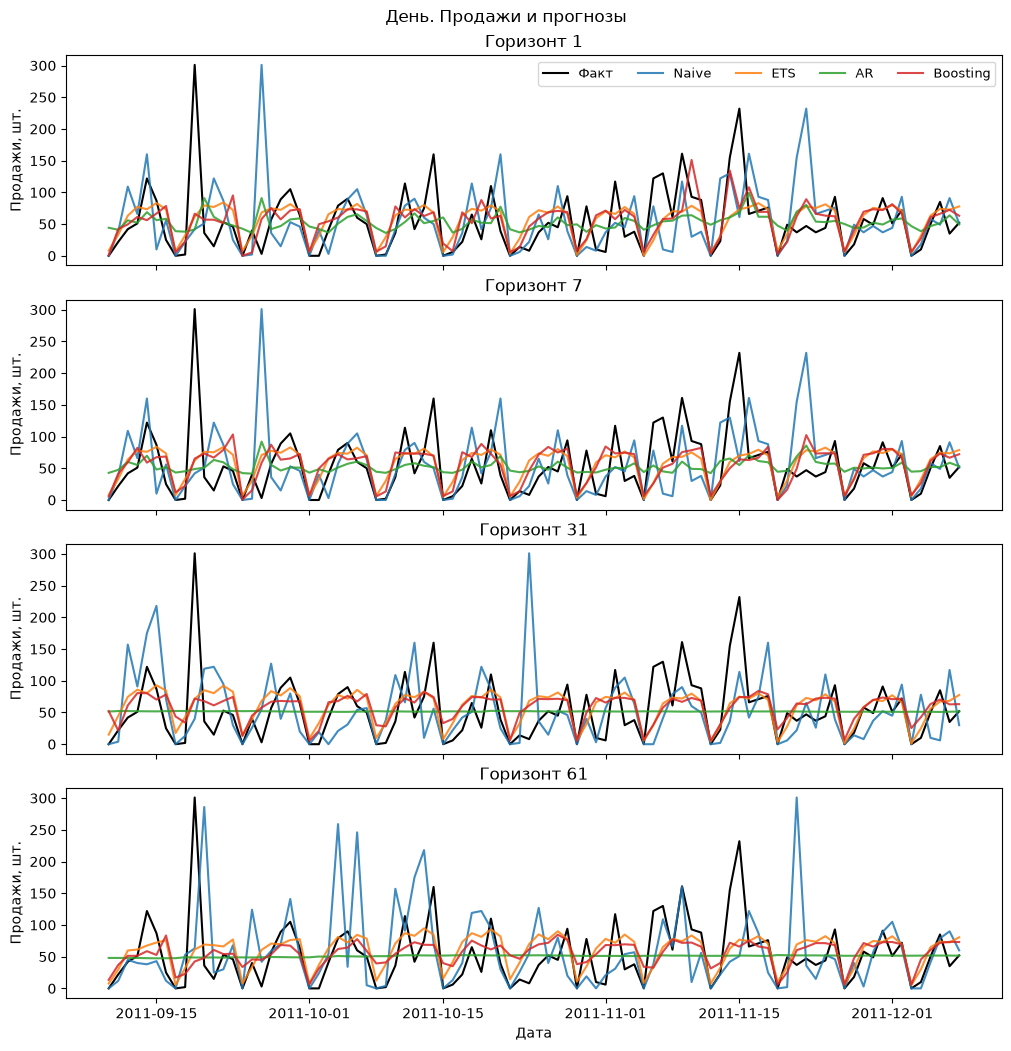

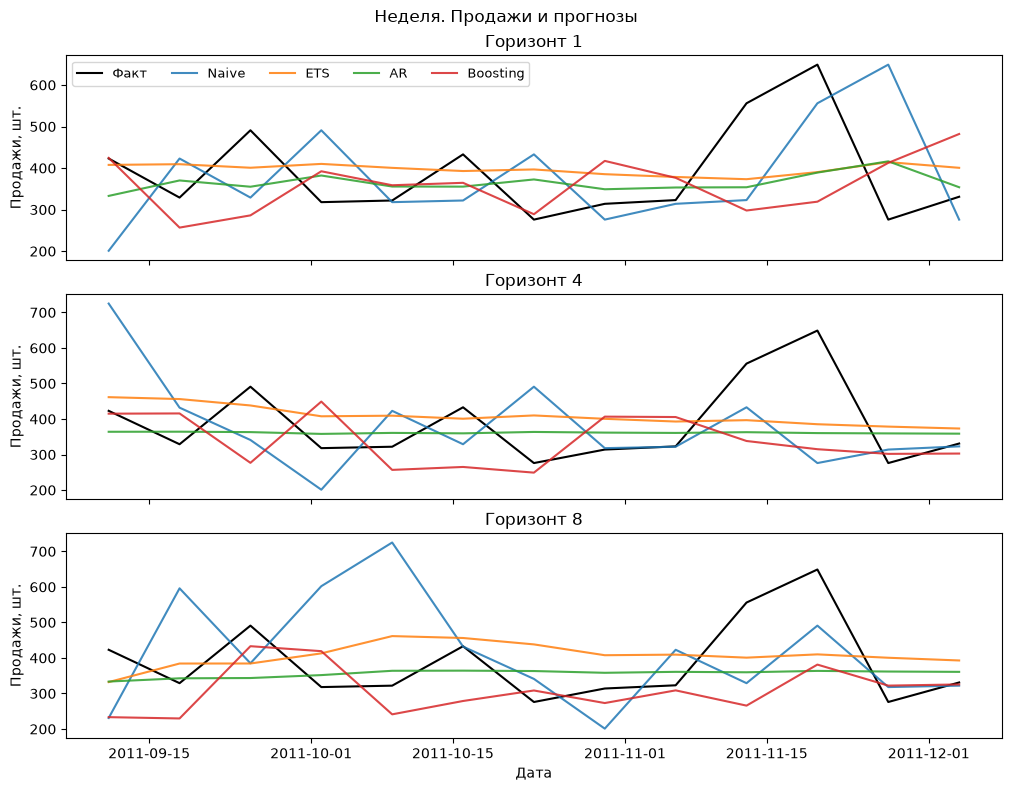

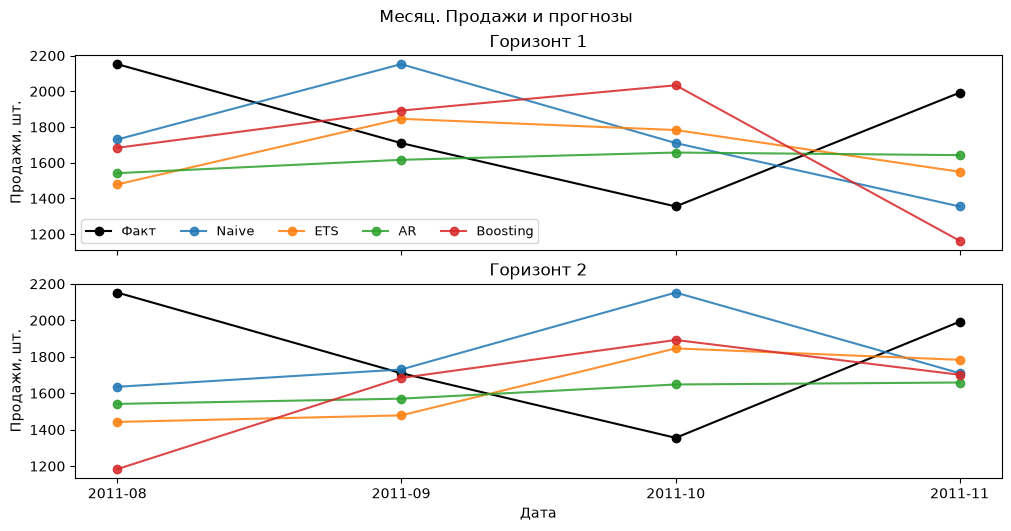

In [5]:
def plot_forecasts(predictions, name, horizons):
    fig, axes = plt.subplots(len(horizons), figsize=(10, 2.6 * len(horizons)), sharex=True, layout="constrained")
    for ax, h in zip(axes, horizons):
        group = predictions.loc[(predictions["frequency"] == name) & (predictions["horizon"] == h)]
        forecast = group.pivot(index="date", columns="model", values="prediction")
        actual = group.drop_duplicates("date").set_index("date")["actual"].sort_index()
        marker = "o" if name == "Месяц" else None
        ax.plot(actual, label="Факт", color="black", linewidth=1.5, marker=marker)
        for model in ["Naive", "ETS", "AR", "Boosting"]:
            ax.plot(forecast[model], label=model, alpha=0.85, marker=marker)
        ax.set(title=f"Горизонт {h}", ylabel="Продажи, шт.")
    axes[0].legend(ncol=5, fontsize=9)
    if name == "Месяц":
        axes[-1].set_xticks(actual.index, actual.index.strftime("%Y-%m"))
    axes[-1].set_xlabel("Дата")
    fig.suptitle(f"{name}. Продажи и прогнозы")
    plt.show()


for name, (_, _, horizons, _) in settings.items():
    plot_forecasts(predictions, name, horizons)

Посмотрим как меняется WAPE с горизонтом. Ниже выведем лучшую модель для каждой пары частоты и горизонта.

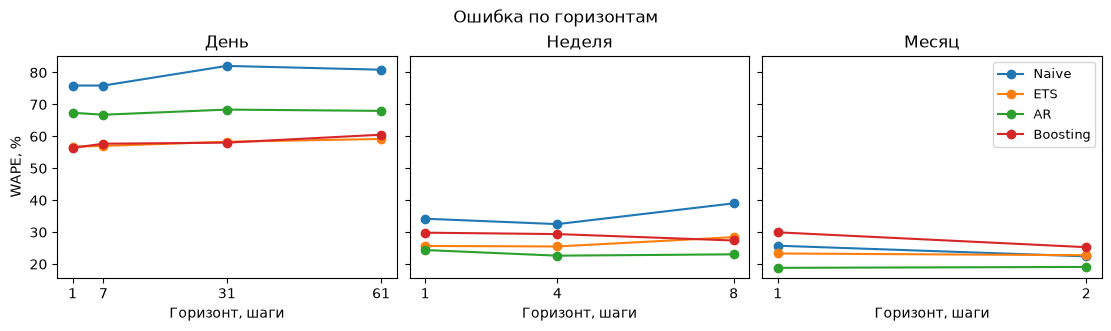

model  WAPE, %
frequency horizon                   
День      1        Boosting    56.40
          7             ETS    57.01
          31       Boosting    58.03
          61            ETS    59.18
Месяц     1              AR    18.81
          2              AR    19.10
Неделя    1              AR    24.39
          4              AR    22.63
          8              AR    23.04

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True, layout="constrained")
for ax, (name, (_, _, horizons, _)) in zip(axes, settings.items()):
    group = metrics.loc[metrics["frequency"] == name]
    for model in ["Naive", "ETS", "AR", "Boosting"]:
        scores = group.loc[group["model"] == model]
        ax.plot(scores["horizon"], scores["WAPE, %"], marker="o", label=model)
    ax.set(title=name, xlabel="Горизонт, шаги", xticks=horizons)
axes[0].set_ylabel("WAPE, %")
axes[-1].legend(fontsize=9)
fig.suptitle("Ошибка по горизонтам")
plt.show()

winners.set_index(["frequency", "horizon"])[["model", "WAPE, %"]].round(2)

## Выводы

- На днях бустинг впереди на 1 и 31 шаге, ETS на 7 и 61. Лучший WAPE растёт с 56,4% до 59,2%. На графиках видно, что обе модели сглаживают пики, а наивная повторяет их в другие даты.
- На неделях AR выигрывает на всех горизонтах. WAPE около 23–24%, заметного роста ошибки с горизонтом здесь нет.
- На месяцах AR тоже выигрывает на обоих горизонтах, WAPE около 19%. В тесте всего 4 месяца, поэтому по этому ряду сложно судить о преимуществе модели.